---
title: Analysing macrophage turnover
author: Nick Savill
format: 
    revealjs:
        code-line-numbers: false
        echo: true
    # typst:
    #     code-line-numbers: false
    #     echo: true
incremental:
    true
theme:
    dracula
slide-level:
    3
jupyter: 
    python3
---

### Learning objectives

- Be able to follow a typical statistical analysis workflow 
- Be able to use and interpret the output of linear models
- Be able to draw conclusions from statistical outputs
- Be able to interpret the data in relation to the hypothesis

### Workflow of statistical analysis

Before we start analysing the data we assume 

1. the data have been entered into a spreadsheet and any data-entry errors have been corrected.

2. the data are in tidy (or long) format:

    - Each row is an observation
    - Each column is a variable

. . .

These are important steps and take time to get right - but we'll assume they have already been done.

### Workflow of statistical analysis {.smaller}

1. In your statistical software, read in the data and plot it for a clearer understanding of the structure of the data
2. If necessary, transform any variables to make them linear and replot
3. Write down your model: describes how the (possibly transformed) response variable is related to the (possibly transformed) explanatory variables
4. Fit your model to the data. This automatically performs any statistical tests
5. Check that the model actually fits the data
6. If necessary, simplify your model and iterate steps 4 to 6 to obtain a model with the fewest parameters 
7. Make inferences (conclusions) about your biological questions and hypotheses from the model fit
    - parameter estimates with confidence intervals
    - tests for significance

### Gut macrophage turnover

#### Tovah's questions

::: {.noincrementall}

1. What are the half-lives of different gut macrophage subpopulations and are they significantly different from one another?

2. Does macrophage turnover occur at the same rate in the small and large intestines?

:::

### Gut macrophage turnover

Data that was collected

- The proportion of macrophages in each subpopulation in the small and large intestines expressing YFP induced by tamoxifen recorded weekly over four weeks.

- Five replicates per time point.

- Positive control (blood monocytes) and negative controls (brain microglia).

### Half-life

The half-life of something - be it radioactive nuclei, macrophages, drugs, etc. - is the time it takes for the amount of that thing to halve.

. . .

:::: {.columns}

::: {.column width="50%"}

For example, the half-life of paracetamol is about 1 hour. It is metabolised in the liver and excreted in urine. So if you take a 400mg tablet at 9am, by 10am you'll have 200mg left in your body and by 11am you'll have 100mg in your body, and so on.

:::

::: {.column width="50%"}
![](Figures/paracetamol.svg){}
:::

::::

### Constant half-life is exponential decay {.smaller}

Things that decay with a constant half-life (i.e., the half-life dose not change with time) are said to decay exponentially. The formula that describes exponential decay is 

$$y(t) = y_0 \exp\left(-\frac{\ln 2}{t_{1/2}}t\right)$$

- $t$ is time
- $y(t)$ is the amount or concentration of the thing decaying at time $t$
- $y_0$ is the amount or concentration at the start when $t=0$
- $\ln 2$ is the natural log of 2 (which is 0.6931...)
- $t_{1/2}$ is the half-life.

### How can we tell if something decays exponentially?

Something that decays exponentially will appear as a straight line in a semi-log plot. Time is on the $x$-axis and the log of amount or concentration is on the $y$-axis.

![](Figures/paracetamol_log.svg){fig-align="center"}

(The maths are in the jupyter notebook).

### An example dataset

- We want **you** to analyse the gut macrophage data.
- So we will walk through an analysis of a different dataset that exhibits exponential decay.
- You will use the same procedure for the macrophage data.

### An example dataset

- Consider two drugs called A and B that relieve pain in humans. The speed with which they relieve pain is related to how fast the drugs are metabolised in the body: faster metabolism relieves pain quicker. 
- Our question is, which drug, if any, metabolises faster?
- In a medical trial drug A is given to five volunteers and drug B is given to four volunteers. 
- The concentration (in mg/L) of each drug in the blood of each volunteer is measured every hour for five hours.

In [2]:
#| echo: false
import pandas as pd
from numpy import log
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols
sns.set_theme('talk')

### Read in the data {.smaller .scrollable}

In [3]:
drugs = pd.read_csv('Data/drug_data.csv')
drugs

,drug,replicate,hour,concentration
0,A,1,0,169.468
1,A,1,1,5.644
2,A,1,2,4.459
3,A,1,3,3.940
4,A,1,4,3.169
5,A,1,5,1.479
6,A,2,0,182.933
7,A,2,1,14.016
8,A,2,2,4.035
9,A,2,3,17.807


. . .

Four columns:

column name | description
:-- | :--
drug | either drug A or drug B
replicate | a number for each volunteer
hour | time since drug was taken in hours
concentration | the concentration of the drug (mg/L)

### For clarity, let's start with examining drug A data

(You would normally analyse both drugs simultaneously)

Select only drug A data from the dataframe


In [4]:
drugA = drugs.query('drug == "A"').copy()

### Plot drug A data {.nonincremental}

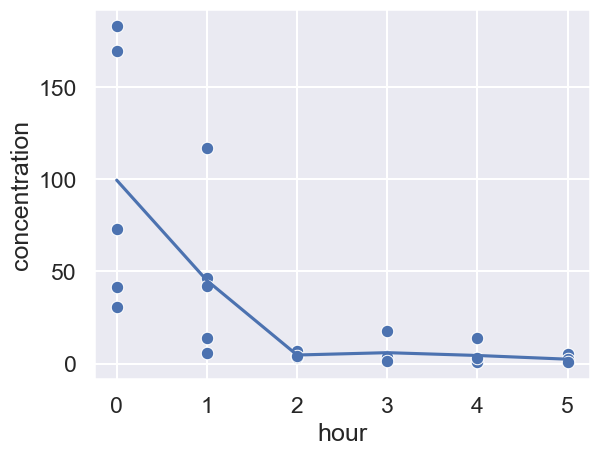

In [5]:
sns.lineplot(data=drugA, x='hour', y='concentration', err_style=None);
sns.scatterplot(data=drugA, x='hour', y='concentration');

### Semi-log plot to see if decay is exponential

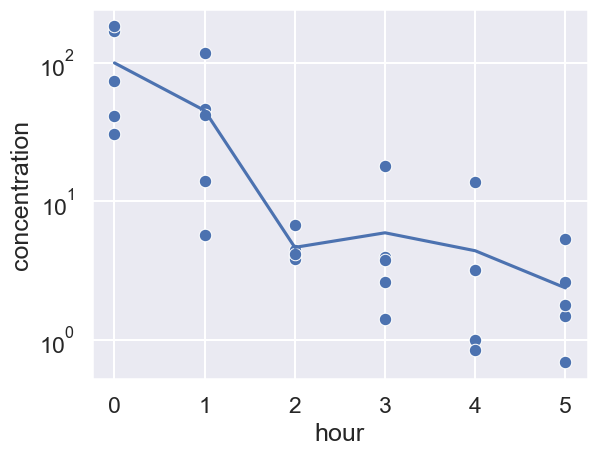

In [8]:
ax = sns.lineplot(data=drugA, x='hour', y='concentration', err_style=None);
sns.scatterplot(data=drugA, x='hour', y='concentration')
ax.set_yscale('log');

### Log-transform concentration {.smaller .scrollable}

In [9]:
drugA['log_conc'] = log(drugA['concentration'])
drugA

,drug,replicate,hour,concentration,log_conc
0,A,1,0,169.468,5.132664
1,A,1,1,5.644,1.730593
2,A,1,2,4.459,1.494925
3,A,1,3,3.940,1.371181
4,A,1,4,3.169,1.153416
5,A,1,5,1.479,0.391366
6,A,2,0,182.933,5.209120
7,A,2,1,14.016,2.640200
8,A,2,2,4.035,1.395006
9,A,2,3,17.807,2.879592


### Use seaborn to plot a linear regression line with 95% confidence band {.smaller}

:::: {.columns}

::: {.column width="50%"}


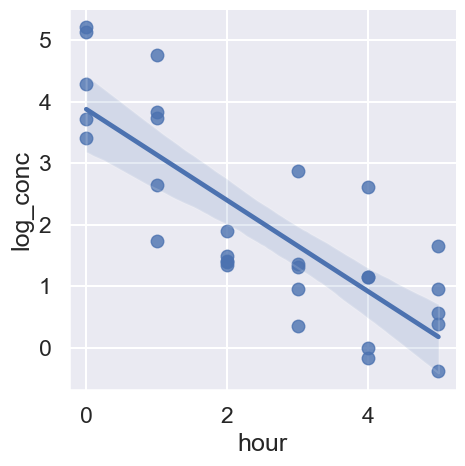

In [9]:
sns.lmplot(data=drugA, x='hour', y='log_conc');

:::

::: {.column width="50%"}
The 95% confidence band indicates our uncertainty in the rate of decay

There is uncertainty because there is a limited amount of data: more data means less uncertainty

Although seaborn has already plotted the linear regression line, we still need to fit a linear model to estimate the half-life
:::
::::

### What is a linear model?

A linear model is our guess about how the response variable is linearly related to the explanatory variables

### What is a linear model?

![](Figures/drugA_log_conc_time.svg){fig-align="center"}

So our model is

**log(concentration) is linearly related to time since administration**

### What is a linear model?

For the computer to fit this model to the data we write it as a formula like so

```python
formula = 'log_conc ~ hour'
```

Where `log_conc` and `hour` are the response and explanatory variables in our dataframe.

### Fit the linear model to the data {.smaller}

In [10]:
# the formula for our model
formula = 'log_conc ~ hour'

# fit the model to the data (in dataframe drugA)
fit = ols(formula, drugA).fit()

# output a summary of the model fit
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.311,12.464,0.000,3.241,4.515
hour,-0.7397,0.103,-7.198,0.000,-0.950,-0.529


### Fit the linear model to the data {.smaller}

In [11]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.311,12.464,0.000,3.241,4.515
hour,-0.7397,0.103,-7.198,0.000,-0.950,-0.529


To draw a straight line you need two pieces of information

::: { .nonincremental}
- its y-intercept (where the line crosses the $y$-axis)
- its slope or gradient
:::
![](Figures/drugA.svg){fig-align="center"}

### Check that the model fits the data

Pearson residuals are often used as a way of checking that the model fits the data well.

![](Figures/residuals.svg){fig-align="center"}

### Check that the model fits the data

Pearson residuals are obtained by dividing the raw residuals by their standard deviation. This is called standardisation.

![](Figures/residuals.svg){fig-align="center"}

### Check that the model fits the data {.smaller .scrollable}

Add Pearson residuals to our dataframe.

In [12]:
drugA['residuals'] = fit.resid_pearson
drugA

,drug,replicate,hour,concentration,log_conc,residuals
0,A,1,0,169.468,5.132664,1.305331
1,A,1,1,5.644,1.730593,-1.464334
2,A,1,2,4.459,1.494925,-0.940047
3,A,1,3,3.940,1.371181,-0.299327
4,A,1,4,3.169,1.153416,0.243586
5,A,1,5,1.479,0.391366,0.220288
6,A,2,0,182.933,5.209120,1.384866
7,A,2,1,14.016,2.640200,-0.518087
8,A,2,2,4.035,1.395006,-1.043990
9,A,2,3,17.807,2.879592,1.269846


### Check that the model fits the data

We plot the Pearson residuals against each of our explanatory variables.

We are looking for a cloud of points without any structure or trend. 

Because Pearson residuals are standardised they should be roughly distributed between ±2.

### Check that the model fits the data

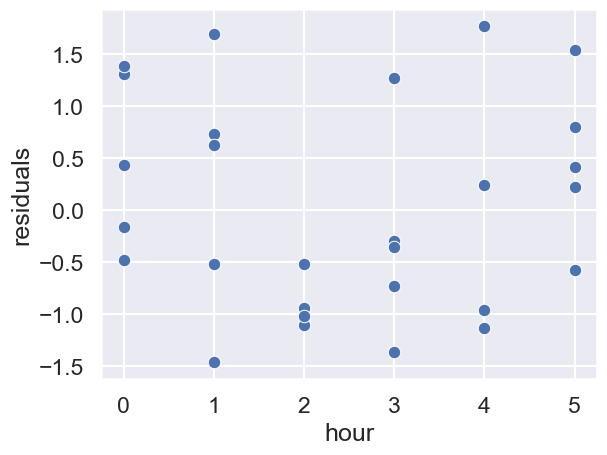

In [13]:
sns.scatterplot(data=drugA, x='hour', y='residuals');

Pearson residuals should not be correlated with the explanatory variables.

### A poor fitting model 

Pearson residuals are correlated with hour.

![](Figures/residuals_poor.svg)

### Interpreting the output of the model fit {.smaller}

In [14]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.311,12.464,0.000,3.241,4.515
hour,-0.7397,0.103,-7.198,0.000,-0.950,-0.529


The **coef** column gives us the estimated mean of the parameters: 3.88 for the *y*-intercept and -0.74 for the slope.

**std err** means "standard error". This column gives us a measure of the uncertainty in those estimates, 3.88 ± 0.31 for the y-intercept and -0.74 ± 0.10 for the slope.

![](Figures/drugA.svg){fig-align="center"}

### Interpreting the output of the model fit {.smaller}

In [15]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.311,12.464,0.000,3.241,4.515
hour,-0.7397,0.103,-7.198,0.000,-0.950,-0.529


The rest of each row is a statistical test (a t-test) of whether that estimate is significantly different from zero.

- Column **t** contains the $t$-statistic of each test. It's value is just **coef** divided by **std err**.

- For the y-intercept $t=-\frac{3.8779}{0.311} = 12.464$.

### Interpreting the output of the model fit {.smaller}

In [16]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.311,12.464,0.000,3.241,4.515
hour,-0.7397,0.103,-7.198,0.000,-0.950,-0.529


- **P>|t|** The *p*-value, the compatibility of the data with the null hypothesis of `coef` equal to zero.

- The estimated y-intercept of 3.88 ± 0.31 is far from zero. Therefore it is incompatible with the null hypothesis of being zero. In fact it's so small that the *p*-value appears to be zero.

- A *p*-value can never be zero. In this case it's so small it just looks like zero. In fact it's value is $6\times 10^{-13}$ (You can find this value by running `fit.pvalues`.)

- When *p*-values are this small we usually write "*p* < 0.001" rather than give its exact value.

- Having said all that, we're not interested in the y-intercept. There is nothing biologically interesting about it. What we are interested in is the slope.

### Interpreting the output of the model fit {.smaller}

In [17]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.311,12.464,0.000,3.241,4.515
hour,-0.7397,0.103,-7.198,0.000,-0.950,-0.529


- For the slope $t=-\frac{-0.7397}{0.103} = -7.198$.

- Its *p*-value is also < 0.001.

- Which means, the slope of -0.74 is incompatible with the null hypothesis of being zero.

### Interpreting the output of the model fit {.smaller}

In [18]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.311,12.464,0.000,3.241,4.515
hour,-0.7397,0.103,-7.198,0.000,-0.950,-0.529


- The columns **[0.025 0.975]** are the 95% confidence interval (CI) of the estimated slope

- Like **std err**, the 95% CI is another measure of our uncertainty in the estimate

- If a 95% CI contains zero, then its *p*-value will be greater than 0.05. In that case the estimated parameter is compatible with the null hypothesis. We would say the slope is **not** significantly different from zero.

- If a 95% CI does not contain zero, then its *p*-value will be less than 0.05. In that case the estimated parameter is incompatible with the null hypothesis. We would say the slope is significantly different from zero.

- As the *p*-values for both the slope and intercept are < 0.001 (and their 95% CI do not contain zero) we can say both are significantly different from zero.

### Now compare drugs A and B

### Log-transform concentration {.smaller .scrollable}

In [20]:
drugs['log_conc'] = log(drugs['concentration']).dropna()
drugs

,drug,replicate,hour,concentration,log_conc
0,A,1,0,169.468,5.132664
1,A,1,1,5.644,1.730593
2,A,1,2,4.459,1.494925
3,A,1,3,3.940,1.371181
4,A,1,4,3.169,1.153416
5,A,1,5,1.479,0.391366
6,A,2,0,182.933,5.209120
7,A,2,1,14.016,2.640200
8,A,2,2,4.035,1.395006
9,A,2,3,17.807,2.879592


### Use seaborn to plot a linear regression line with 95% confidence bands

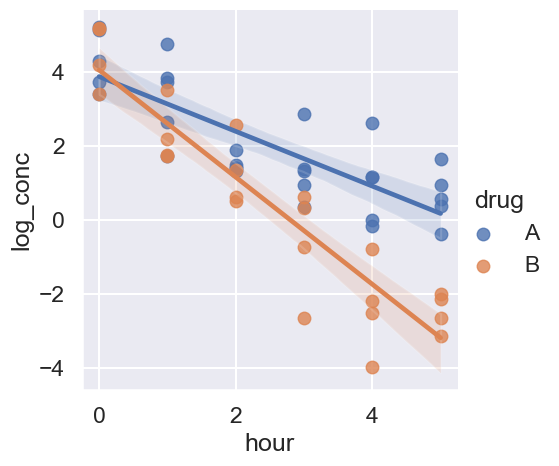

In [21]:
sns.lmplot(data=drugs, x='hour', y='log_conc', hue='drug');

### Fit a linear model

The formula to test for a difference in decay rates between drugs A and B is

```python
formula = 'log_conc ~ drug * hour'
```
- Do not read this formula like a mathematical formula!

- This formula means log(concentration) is **linearly related (~)** to the combination of the `drug` given (A or B) and to the `hour` since administration.  

### Some statistical terminology: Factors, levels and variates

- A **factor** is a categorical explanatory variable

    - `drug` is a factor

- A factor has two or more **levels**

    - the levels of the factor `drug` are `A` and `B`

- A **variate** is a numerical explanatory variable

    - `hour` is a variate

### Fit our linear model to the drug data {.smaller}

In [22]:
formula = 'log_conc ~ drug*hour'
fit = ols(formula, drugs).fit()
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.325,11.931,0.000,3.225,4.531
drug[T.B],0.1778,0.488,0.365,0.717,-0.801,1.157
hour,-0.7397,0.107,-6.890,0.000,-0.955,-0.524
drug[T.B]:hour,-0.7069,0.161,-4.390,0.000,-1.030,-0.383


### Check that the model fits the data

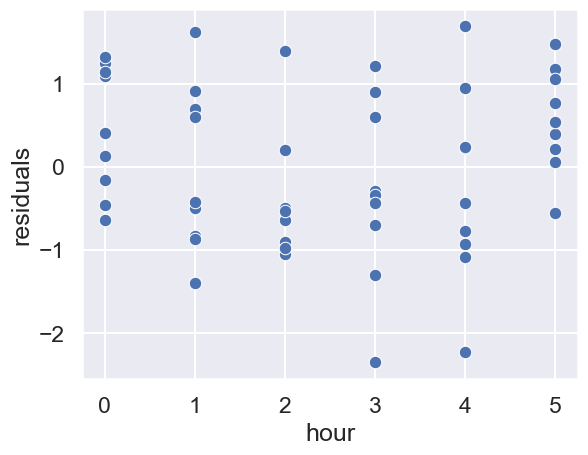

In [23]:
drugs['residuals'] = fit.resid_pearson
sns.scatterplot(data=drugs, x='hour', y='residuals');

### Check that the model fits the data

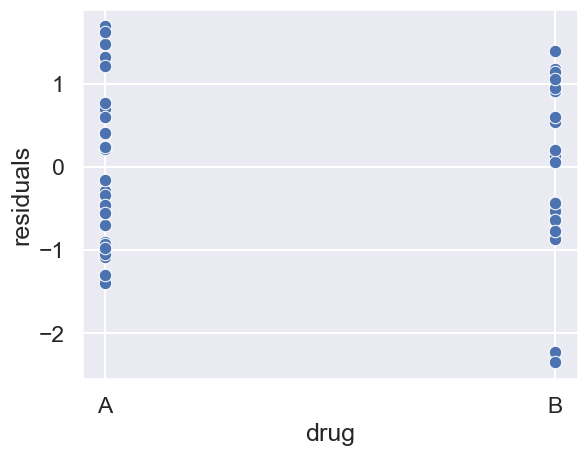

In [24]:
sns.scatterplot(data=drugs, x='drug', y='residuals');

### Interpreting the output of the model fit {.smaller}

In [25]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.325,11.931,0.000,3.225,4.531
drug[T.B],0.1778,0.488,0.365,0.717,-0.801,1.157
hour,-0.7397,0.107,-6.890,0.000,-0.955,-0.524
drug[T.B]:hour,-0.7069,0.161,-4.390,0.000,-1.030,-0.383


First notice that the `Intercept` and `hour` rows are the same as before

![](Figures/drug_refA.svg){fig-align="center"}

### Interpreting the output of the model fit

- The fitting procedure has taken drug A as the reference level.

- By default the reference level is the first alphabetically. But you can change this.

- The parameters for drug B are estimated **relative** to drug A. 
    - That is, the procedure calculates the differences in the y-intercepts and the differences in the slopes between drugs A and B.

### Interpreting the output of the model fit {.smaller}

In [26]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.325,11.931,0.000,3.225,4.531
drug[T.B],0.1778,0.488,0.365,0.717,-0.801,1.157
hour,-0.7397,0.107,-6.890,0.000,-0.955,-0.524
drug[T.B]:hour,-0.7069,0.161,-4.390,0.000,-1.030,-0.383


Row `drug[T.B]` is the **difference** between the y-intercepts of drugs A and B.

![](Figures/drugs_D_intercept.svg){fig-align="center"}

### Interpreting the output of the model fit {.smaller}

In [27]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.325,11.931,0.000,3.225,4.531
drug[T.B],0.1778,0.488,0.365,0.717,-0.801,1.157
hour,-0.7397,0.107,-6.890,0.000,-0.955,-0.524
drug[T.B]:hour,-0.7069,0.161,-4.390,0.000,-1.030,-0.383


Row `drug[T.B]:hour` is the **difference** between the slopes of drugs A and B. 

![](Figures/drugs_D_slopes.svg){fig-align="center"}

### Interpreting the output of the model fit {.smaller}

In [28]:
#| echo: false
fit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.325,11.931,0.000,3.225,4.531
drug[T.B],0.1778,0.488,0.365,0.717,-0.801,1.157
hour,-0.7397,0.107,-6.890,0.000,-0.955,-0.524
drug[T.B]:hour,-0.7069,0.161,-4.390,0.000,-1.030,-0.383


- The *p*-value of the test that the difference between the slopes is different from zero is < 0.001.

- The confidence interval for the difference between the slopes is (-1.03, -0.38). It does not contain zero.

- Therefore, there is a significant difference between the slopes. 

- Which means drugs A and B have significantly different decay rates and, therefore, half-lives.

### Change the reference level of a factor

By default the reference level is the first alphabetically. So drug A is the reference.

This can be changed so that drug B is the reference.

```python
# drug A is the reference level by default
formula = 'log_conc ~ drug * hour'

# change reference level to drug B
formula = 'log_conc ~ C(drug, Treatment("B")) * hour'
```

### Change the reference level of a factor {.smaller}

In [33]:
#| echo: false
formula = 'log_conc ~ C(drug, Treatment("A")) * hour'
fit_refB = ols(formula, drugs).fit()
fit_refB.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,3.8779,0.325,11.931,0.000,3.225,4.531
"C(drug, Treatment(""A""))[T.B]",0.1778,0.488,0.365,0.717,-0.801,1.157
hour,-0.7397,0.107,-6.890,0.000,-0.955,-0.524
"C(drug, Treatment(""A""))[T.B]:hour",-0.7069,0.161,-4.390,0.000,-1.030,-0.383


In [34]:
#| echo: false
formula = 'log_conc ~ C(drug, Treatment("B")) * hour'
fit_refA = ols(formula, drugs).fit()
fit_refA.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,4.0557,0.363,11.161,0.000,3.326,4.786
"C(drug, Treatment(""B""))[T.A]",-0.1778,0.488,-0.365,0.717,-1.157,0.801
hour,-1.4465,0.120,-12.052,0.000,-1.688,-1.205
"C(drug, Treatment(""B""))[T.A]:hour",0.7069,0.161,4.390,0.000,0.383,1.030


### Estimate half-lives of drugs A and B

Half-life $t_{1/2}$, is related to decay rate $r$, by the formula

$$t_{1/2} = \frac{\ln 2}{r}$$

(The maths, if you're interested, is in the macrophage notebook)

- The decay rate and its standard error are available from the summary tables

### Estimate half-lives of drugs A and B

In [31]:
print('Estimated parameters')
mu = fit.params
print(mu)

print('')
print('Uncertainty (standard error) in the estimates')
se = fit.bse
print(se)

Estimated parameters
Intercept         3.877879
drug[T.B]         0.177773
hour             -0.739654
drug[T.B]:hour   -0.706854
dtype: float64

Uncertainty (standard error) in the estimates
Intercept         0.325013
drug[T.B]         0.487519
hour              0.107348
drug[T.B]:hour    0.161022
dtype: float64


### Estimate half-lives of drugs A and B

In [36]:
# estimated decay rates
rA = -mu['hour']
rB = -mu['hour'] - mu['drug[T.B]:hour']

# estimated half-lives
thalfA = log(2)  / rA
thalfB = log(2)  / rB

print(f'estimated half life of drug A = {thalfA:.2f} h')
print(f'estimated half life of drug B = {thalfB:.2f} h')

estimated half life of drug A = 0.94 h
estimated half life of drug B = 0.48 h


- As half-life is the inverse of decay rate, uncertainty in the half-life estimates is not simple to calculate. So we won't do that here. 

### Report the result

The decay rates of drugs A and B are significantly different ($\Delta r = 0.71\pm 0.16\ \text{h}^{-1}$, 95% CI = (0.38, 1.03), $t=4.4$, $p<0.001$). The half-life of drug A is 0.94 h and the half-life of drug B is 0.48 h.

### Case study 2, Tovah's experiments

#### Gut macrophage turnover

The notebook `macrophage_analysis.ipynb` leads you through the analysis of Tovah's data.

The notebook `drug_analysis_workflow.ipynb` is an abridged version of this lecture.

You can copy and paste the code from that notebook into the macrophage notebook and then adapt it for the macrophage dataset. 

### How to access the notebooks

These instructions are also on Learn

1. Log onto Noteable through Learn
2. Start a Standard Python 3 Notebook
3. At the top click **Git** then **Clone a repository**
4. Copy and paste the URL **https://github.com/edinburgh-bto/EDII** into the dialog
5. Make sure to tick **Download the Repository**
6. Click **Clone**
7. The notebooks are in the EDII/Case Study 2 folder